# Ticker Selection

Rationale: choose tickers that are decoupled from the large Indicators (e.g. SPY, QQQ) to minimize the masking effect

In [3]:
import pandas as pd
import numpy as np
import yfinance as yf

# Define the complete combined universe
mid_caps = [
    "FLEX", "TWLO", "FTI", "CW", "NVT", "STRL", "XPO", "EWBC", "RGA", "EVR",    # recommended
    "EXP", "SAIA", "HXL", "BOOT", "MDU"                                         # alternatives
]
small_caps = [
    "BLKB", "CNXC", "CACC", "LAZ", "EBC", "WSBC", "WRBY", "LQDA", "RSI", "USLM",    # recommended
    "KFY", "HNI", "NGS", "CALM"                                                     # alternatives
]
universe = mid_caps + small_caps
benchmarks = ["SPY", "QQQ", "XLI"]

# Download 3 year of daily Adjusted Close prices
print("Downloading historical data...")
all_tickers = universe + benchmarks
raw_data = yf.download(all_tickers, period="3y", auto_adjust=False)
data = raw_data["Adj Close"]

# Calculate daily percentage returns
returns = data.ffill().pct_change(fill_method=None)

[*********************100%***********************]  32 of 32 completed


In [4]:
# function to calculate rolling Beta and R-squared (60-day window)
def calculate_rolling_metrics(asset_returns, benchmark_returns, window=60):
    joint_returns = pd.concat([asset_returns, benchmark_returns], axis=1).dropna()
    clean_asset = joint_returns.iloc[:, 0]
    clean_benchmark = joint_returns.iloc[:, 1]
    
    if len(joint_returns) < window:
        return np.nan, np.nan
    
    rolling_cov = clean_asset.rolling(window=window).cov(clean_benchmark)
    rolling_benchmark_var = clean_benchmark.rolling(window=window).var()
    rolling_asset_var = clean_asset.rolling(window=window).var()
    
    rolling_beta = rolling_cov / rolling_benchmark_var
    rolling_r2 = (rolling_cov ** 2) / (rolling_asset_var * rolling_benchmark_var)
    
    return rolling_beta.iloc[-1], rolling_r2.iloc[-1]

# Compute metrics across all stocks and benchmarks
results = []
for ticker in universe:
    row = {
        "Ticker": ticker,
        "Segment": "Mid-Cap" if ticker in mid_caps else "Small-Cap"
    }
    for bench in benchmarks:
        if ticker in returns.columns:
            beta, r2 = calculate_rolling_metrics(returns[ticker], returns[bench], window=60)
            row[f"Beta_{bench}"] = beta
            row[f"R2_{bench}"] = r2
            
    results.append(row)

# Convert to DataFrame
results_df = pd.DataFrame(results).set_index("Ticker")

# filter out stocks with the highest Max R2
# This finds the maximum systematic coupling for each stock across the 3 benchmarks
results_df['Max_R2'] = results_df[['R2_SPY', 'R2_QQQ', 'R2_XLI']].max(axis=1)

# Select Top 10 from each segment
# Sort ascending by Max_R2 (lowest R2 = most decoupled)
mid_cap_candidates = results_df[results_df["Segment"] == "Mid-Cap"].sort_values(by="Max_R2")
small_cap_candidates = results_df[results_df["Segment"] == "Small-Cap"].sort_values(by="Max_R2")

selected_mid_caps = mid_cap_candidates.head(10)
selected_small_caps = small_cap_candidates.head(10)

# Combine into the final 20-stock portfolio
final_portfolio = pd.concat([selected_mid_caps, selected_small_caps])

# 8. Display Results
print("\n" + "="*90)
print("             FINAL STRATIFIED 20-STOCK PORTFOLIO (10 MID-CAPS / 10 SMALL-CAPS)")
print("                 (Sorted by lowest Max R-Squared - Most Decoupled First)")
print("="*90)

def print_formatted_table(df_segment, title):
    print(f"\n>>> {title}")
    header = f"{'Ticker':<7} | {'Max R2':<8} | {'Beta SPY':<8} | {'R2 SPY':<8} | {'Beta QQQ':<8} | {'R2 QQQ':<8} | {'Beta XLI':<8} | {'R2 XLI':<8}"
    print(header)
    print("-" * len(header))
    
    for idx, row in df_segment.iterrows():
        print(f"{idx:<7} | "
              f"{row['Max_R2']:7.1%} | "
              f"{row['Beta_SPY']:8.2f} | "
              f"{row['R2_SPY']:7.1%} | "
              f"{row['Beta_QQQ']:8.2f} | "
              f"{row['R2_QQQ']:7.1%} | "
              f"{row['Beta_XLI']:8.2f} | "
              f"{row['R2_XLI']:7.1%}")

print_formatted_table(selected_mid_caps, "SELECTED MID-CAPS (BIG CAP)")
print_formatted_table(selected_small_caps, "SELECTED SMALL-CAPS")

print("\n" + "="*90)
print(f"Portfolio Average Max R2: {final_portfolio['Max_R2'].mean():.1%}")
print("="*90)


             FINAL STRATIFIED 20-STOCK PORTFOLIO (10 MID-CAPS / 10 SMALL-CAPS)
                 (Sorted by lowest Max R-Squared - Most Decoupled First)

>>> SELECTED MID-CAPS (BIG CAP)
Ticker  | Max R2   | Beta SPY | R2 SPY   | Beta QQQ | R2 QQQ   | Beta XLI | R2 XLI  
------------------------------------------------------------------------------------
FTI     |    1.7% |     0.21 |    0.7% |     0.18 |    1.7% |     0.10 |    0.4%
TWLO    |    3.8% |     1.03 |    3.3% |     0.58 |    3.8% |    -0.47 |    1.5%
MDU     |    6.9% |    -0.31 |    4.5% |    -0.20 |    6.9% |     0.06 |    0.4%
BOOT    |    9.8% |     0.65 |    3.3% |     0.37 |    3.7% |     0.76 |    9.8%
EWBC    |   17.6% |     0.38 |    5.5% |     0.07 |    0.6% |     0.45 |   17.6%
RGA     |   19.5% |    -0.45 |    6.7% |    -0.41 |   19.5% |    -0.04 |    0.1%
XPO     |   19.6% |     0.97 |    9.6% |     0.41 |    6.0% |     0.93 |   19.6%
SAIA    |   22.8% |     1.32 |   15.0% |     0.53 |    8.6% |     1.10 |   22

In [5]:
selected_tickers = final_portfolio.index.tolist()
raw = yf.download(selected_tickers, period="3y", auto_adjust=False)

[*********************100%***********************]  20 of 20 completed


In [6]:
# melt the raw data to long format for easier analysis
df = raw.stack(level=1)
df = df.reset_index()
df

Price,Date,Ticker,Adj Close,Close,High,Low,Open,Volume
0,2023-07-18,BOOT,92.099998,92.099998,94.110001,91.294998,93.220001,729800
1,2023-07-18,CACC,569.010010,569.010010,571.489990,552.780029,552.780029,87800
2,2023-07-18,CALM,37.895435,44.430000,44.889999,44.040001,44.040001,728900
3,2023-07-18,CNXC,77.386719,83.540001,86.599998,83.400002,85.330002,495600
4,2023-07-18,EVR,130.229141,135.869995,136.179993,134.139999,134.139999,299700
...,...,...,...,...,...,...,...,...
15055,2026-07-17,TWLO,206.779999,206.779999,209.800003,200.050003,202.750000,2413900
15056,2026-07-17,USLM,104.970001,104.970001,109.239998,104.410004,107.620003,102800
15057,2026-07-17,WRBY,26.410000,26.410000,28.620001,26.209999,26.459999,2672600
15058,2026-07-17,WSBC,40.799999,40.799999,41.119999,40.380001,40.590000,1180300


# EDA

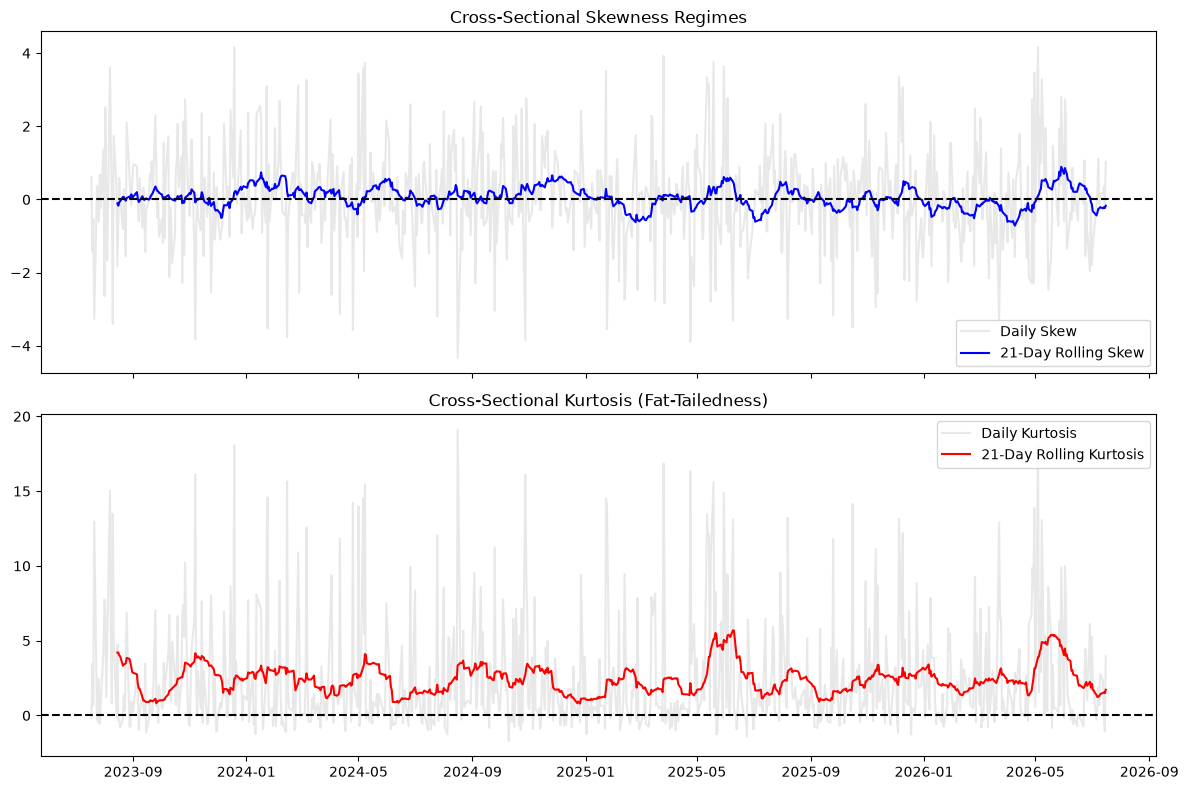

In [7]:
import matplotlib.pyplot as plt

# Calculate the 1-day-forward log return: log(C_{t+1} / C_t)
df['fwd_log_return'] = df.groupby('Ticker')['Adj Close'].transform(
    lambda x: np.log(x.shift(-1) / x)
)

# Calculate the cross-sectional mean for each day: mean_j(r[j, t->t+1])
df['cs_mean_return'] = df.groupby('Date')['fwd_log_return'].transform('mean')

# Subtract the daily mean from each stock's return to get final target
df['target'] = df['fwd_log_return'] - df['cs_mean_return']
df = df.drop(columns=['cs_mean_return'])

daily_dist = df.groupby('Date')['target'].agg(
    skew=lambda x: x.skew(),
    kurt=lambda x: x.kurt()
)

# Apply a 21-day rolling mean to smooth the noise and find regimes
rolling_dist = daily_dist.rolling(window=21).mean()

# Plotting the Regimes
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)


# Skewness
ax[0].plot(daily_dist.index, daily_dist['skew'], color='lightgray', label='Daily Skew', alpha=0.5)
ax[0].plot(rolling_dist.index, rolling_dist['skew'], color='blue', label='21-Day Rolling Skew')
ax[0].axhline(0, color='black', linestyle='--')
ax[0].set_title('Cross-Sectional Skewness Regimes')
ax[0].legend()

# Kurtosis
ax[1].plot(daily_dist.index, daily_dist['kurt'], color='lightgray', label='Daily Kurtosis', alpha=0.5)
ax[1].plot(rolling_dist.index, rolling_dist['kurt'], color='red', label='21-Day Rolling Kurtosis')
ax[1].axhline(0, color='black', linestyle='--') # Baseline normal distribution
ax[1].set_title('Cross-Sectional Kurtosis (Fat-Tailedness)')
ax[1].legend()

plt.tight_layout()

- Cross-sectional skewness: 21-day rolling skewness oscillates around the zero baseline, rarely exceeding +1 or -1. Over the long run, the panel is structurally balanced. There is no permanent bias - the model will have an equal opportunity to find long and short candidates.
- Cross-sectional kurtosis: the red line is always above 0, meaning the daily return distribution is always heavier in the tails than a normal distribution. Should pay attention to fat tailedness in modelling - use MAE or Huber Loss in regression

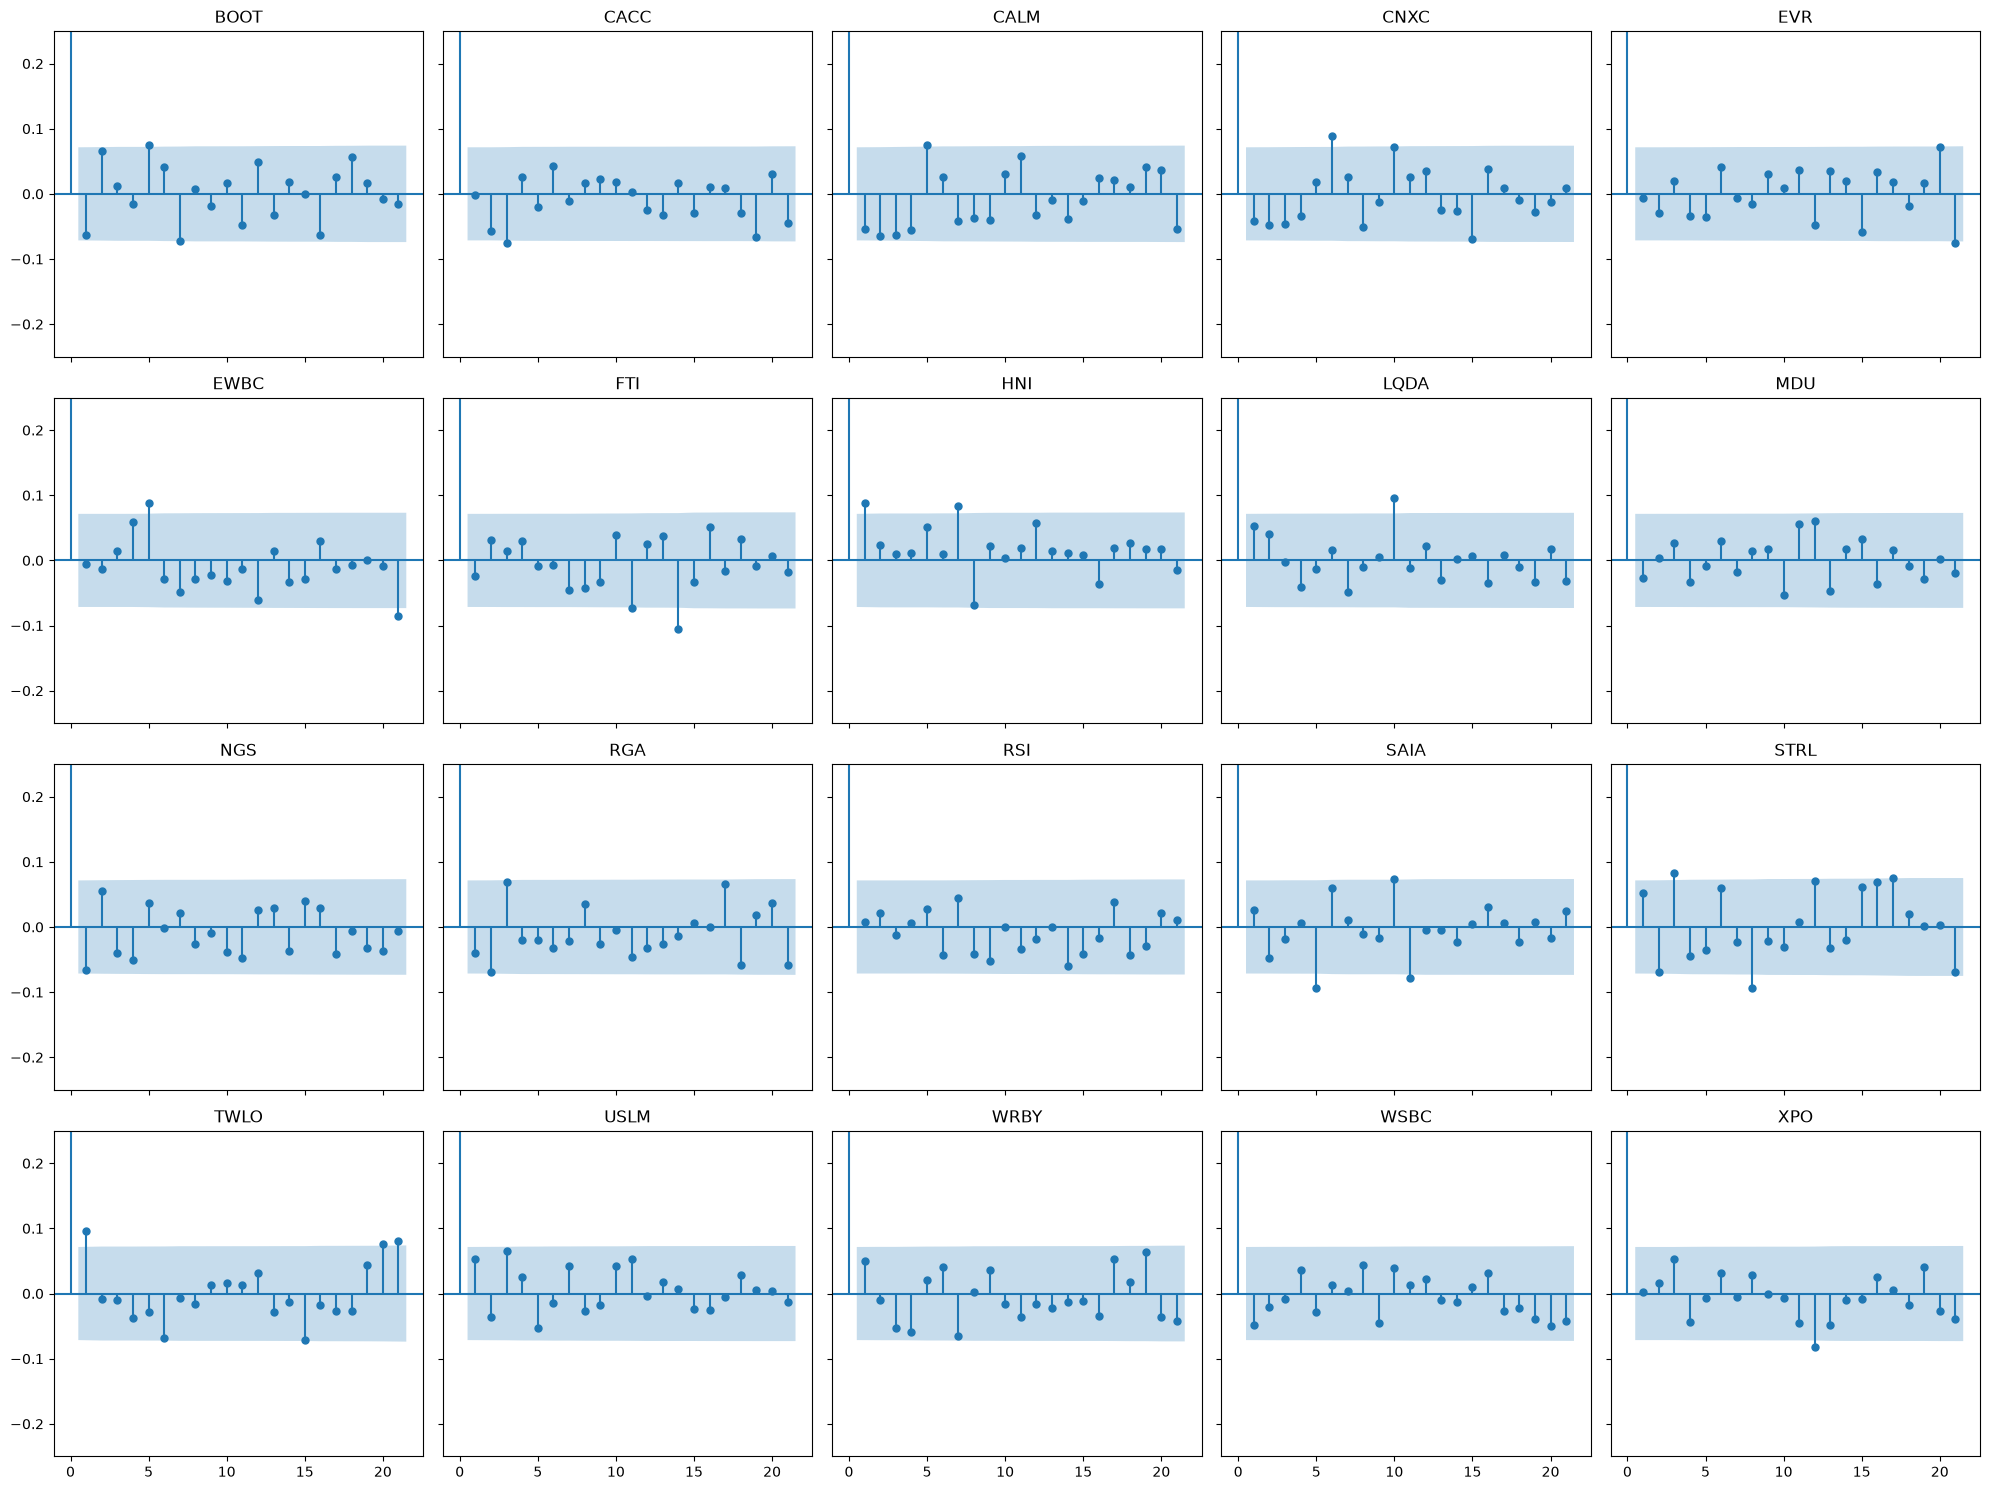

In [8]:
# Autocorrelation Analysis

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

tickers = df['Ticker'].unique()
fig, axes = plt.subplots(4, 5, figsize=(20, 15), sharex=True, sharey=True)
axes = axes.flatten()

# plot ACF
for i, ticker in enumerate(tickers):
    series = df[df['Ticker'] == ticker]['target'].dropna()
    # alpha=0.05 draws the 95% confidence interval
    plot_acf(series, ax=axes[i], lags=21, alpha=0.05, title=ticker)
    axes[i].set_ylim(-0.25, 0.25) 

plt.tight_layout()
plt.show()

- No linear autocorrelation:  cannot forecast tomorrow's relative return simply by regressing it against its own recent returns. Should look more into other external features such as short-interest ratios, put-call imbalances, and cross-sectional liquidity metrics (bid-ask spreads).